## Load and format rasters

In [5]:
states = { # place ids
    "Ohio": 31,
    "Michigan": 29,
    "Indiana": 20,
    "Pennsylvania": 42,
    "Kentucky": 26,
    "West Virginia": 33
}

rasters = {
    'canopy_cover': '/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/nlcd_tcc_conus_wgs84_v2025-6_20250101_20251231.tif',
    'land_cover': '/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/Annual_NLCD_LndCov_2025_CU_C1V2.tif',
    'FctImp': '/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/Annual_NLCD_FctImp_2025_CU_C1V2.tif'
}

categorical = ['land_cover']

In [6]:
# Get bounding polygon for midwest

import geopandas as gdp
from rasterio.mask import mask
import osmnx as ox



regions = list(states.keys())
for state in regions: regions[regions.index(state)] = f'{state}, USA'
regions = ox.geocode_to_gdf(regions)

mastery_boundary = regions.unary_union
boundary_gdf = gdp.GeoSeries([mastery_boundary], crs = regions.crs)
boundary_gdf

/tmp/ipykernel_4954/3970371861.py:13: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  mastery_boundary = regions.unary_union


,0
0,"MULTIPOLYGON (((-89.56682 36.56422, -89.56318 ..."


In [7]:
# Clip rasters to midwest

import subprocess
import os
import geopandas as gpd
import rasterio



clipped_rasters = {}

for raster in rasters:
    with rasterio.open(rasters[raster]) as src:
        # Reproject crs
        if boundary_gdf.crs != src.crs:
            print(f'Reprojecting states from {boundary_gdf.crs} to {src.crs}')
            boundary_gdf = boundary_gdf.to_crs(src.crs)
            
    boundary_gdf = boundary_gdf.buffer(0)
            
    # Convert the GeoSeries into a GeoDataFrame table to save it as a GeoPackage
    temp_vector = f"/kaggle/working/temp_bounds_{raster}.gpkg"
    export_gdf = gpd.GeoDataFrame(geometry=boundary_gdf, crs=boundary_gdf.crs)
    export_gdf.to_file(temp_vector, driver="GPKG")
    
    out_path = f'/kaggle/working/{raster}_clipped.tiff'
    print(f"Clipping {raster} via gdalwarp...")
    
    cmd = [
        "gdalwarp",
        "-cutline", temp_vector,
        "-crop_to_cutline",
        rasters[raster],
        out_path
    ]
    
    # Print GDAL error output if it fails
    try:
        subprocess.run(cmd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        print(f"\nGDAL ERROR ON {raster}")
        print(e.stderr) 
        continue 
        
    # Clean up the temporary vector file
    if os.path.exists(temp_vector):
        os.remove(temp_vector)
    
    print(f'Successfully clipped {raster}\t{rasters[raster]}')

    clipped_rasters[f'{raster}_clipped'] = out_path

Reprojecting states from epsg:4326 to PROJCS["Albers_Conical_Equal_Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Clipping canopy_cover via gdalwarp...
Successfully clipped canopy_cover	/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/nlcd_tcc_conus_wgs84_v2025-6_20250101_20251231.tif
Clipping land_cover via gdalwarp...
Successfully clipped land_cover	/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/Annual_NLCD_LndCov_2025_CU_C1V2.tif
Clipping FctImp via gdalwarp...

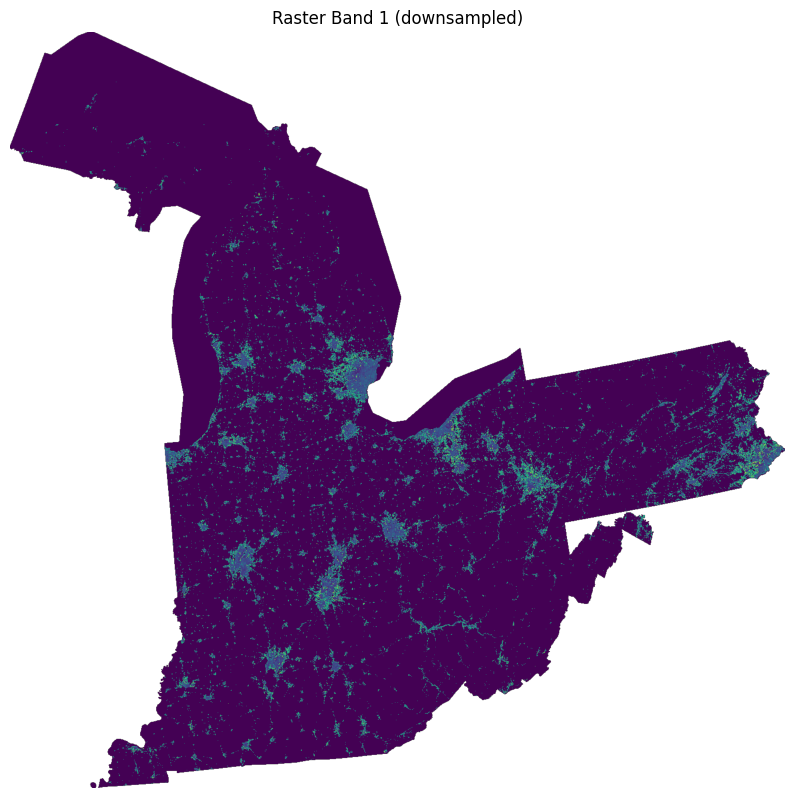

In [8]:
from rasterio.enums import Resampling
import matplotlib.pyplot as plt



max_size = 1500
with rasterio.open(clipped_rasters['FctImp_clipped']) as src:
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image, cmap='viridis')
ax.set_title('Raster Band 1 (downsampled)')
ax.axis('off')
plt.show()

In [9]:
# Reprojecting all rasters to the same crs

from rasterio.warp import calculate_default_transform, reproject, Resampling



dst_crs = 'EPSG:5070'


with rasterio.open(clipped_rasters['land_cover_clipped']) as master_src:
    master_transform, master_width, master_height = calculate_default_transform(
        master_src.crs, dst_crs, master_src.width, master_src.height, *master_src.bounds
    )

reproj_rasters = {}

for raster in clipped_rasters:
    with rasterio.open(clipped_rasters[raster]) as src:
        # Update metadata to snap exactly to the master grid
        kwargs = src.meta.copy()
        kwargs.update({
            'crs': dst_crs,
            'transform': master_transform,
            'width': master_width,
            'height': master_height,
            'nodata': src.nodata
        })

        resample_method = Resampling.bilinear
        for raster_name in categorical:
            if raster_name in raster:
                resample_method = Resampling.nearest
                break

        print(f"Reprojecting {raster} to {dst_crs} using {resample_method}")
        
        output_path = f'/kaggle/working/{raster}_reproj.tiff'
        with rasterio.open(output_path, 'w', **kwargs) as dst:
            for i in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, i),
                    destination=rasterio.band(dst, i),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=master_transform,
                    dst_crs=dst_crs,
                    src_nodata=src.nodata,  # Handle NoData bridging
                    dst_nodata=src.nodata,
                    resampling=resample_method
                )

        reproj_rasters[f'{raster}_reproj'] = output_path

Reprojecting canopy_cover_clipped to EPSG:5070 using 1
Reprojecting land_cover_clipped to EPSG:5070 using 0
Reprojecting FctImp_clipped to EPSG:5070 using 1


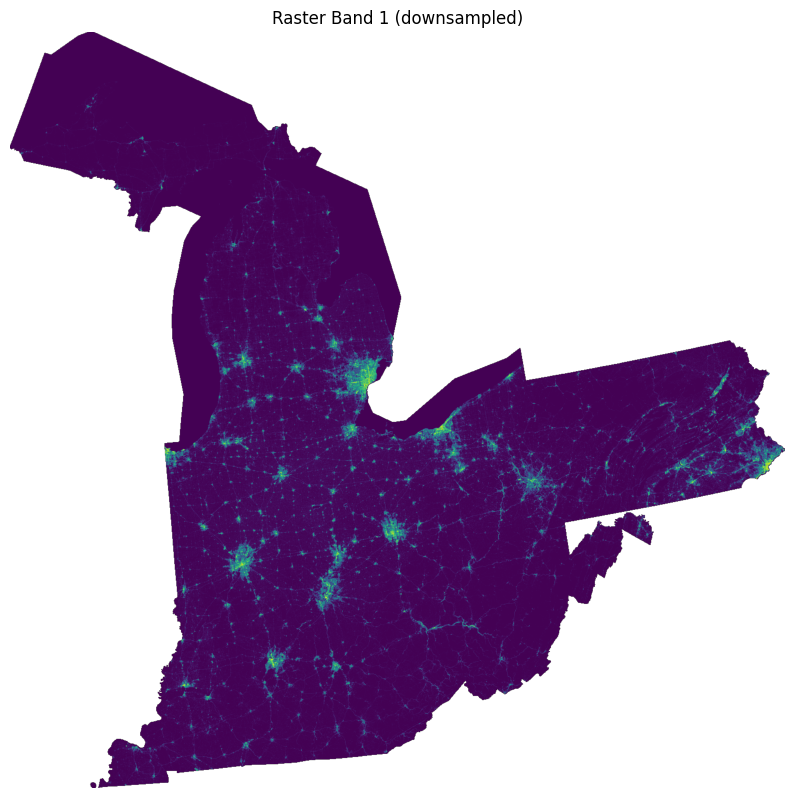

In [10]:
from rasterio.enums import Resampling
import matplotlib.pyplot as plt



max_size = 1500
with rasterio.open(reproj_rasters['FctImp_clipped_reproj']) as src:
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image, cmap='viridis')
ax.set_title('Raster Band 1 (downsampled)')
ax.axis('off')
plt.show()